In [33]:
# ================================================================
# 🧪 Lab: EDA Univariate Analysis - Amazon UK Product Insights
# ================================================================
# Dataset: amz_uk_price_prediction_dataset.csv
# Objective: Explore product listings on Amazon UK to extract insights.
# ================================================================

# --- Setup ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

pd.set_option('display.max_columns', None)
sns.set(style="whitegrid")

# --- Load Dataset ---
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
print("✅ Dataset loaded successfully!")
print("Shape of dataset:", df.shape)
df.head()


✅ Dataset loaded successfully!
Shape of dataset: (2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [35]:
# ================================================================
# Light Data Cleaning
# ================================================================

# Check missing values
print("Missing values per column:\n", df.isna().sum())

# Drop rows with missing essential values
df = df.dropna(subset=['category', 'price'])

# Ensure price is numeric
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Drop invalid or missing prices
df = df.dropna(subset=['price'])

# Keep only reasonable price range (0 < price < 5000)
df = df[(df['price'] > 0) & (df['price'] < 5000)]

print("\n✅ Data cleaned! New shape:", df.shape)
df.head()


Missing values per column:
 uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

✅ Data cleaned! New shape: (2442121, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [36]:
# ================================================================
# Part 1: Understanding Product Categories
# ================================================================

# --- 1.1 Frequency Table ---
category_counts = df['category'].value_counts()
print("Frequency table (top 10):\n", category_counts.head(10))

# --- 1.2 Top 5 Most Listed Categories ---
top5_categories = category_counts.head(5)
print("\nTop 5 Product Categories:")
print(top5_categories)


Frequency table (top 10):
 category
Sports & Outdoors                         835382
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18563
Name: count, dtype: int64

Top 5 Product Categories:
category
Sports & Outdoors                         835382
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


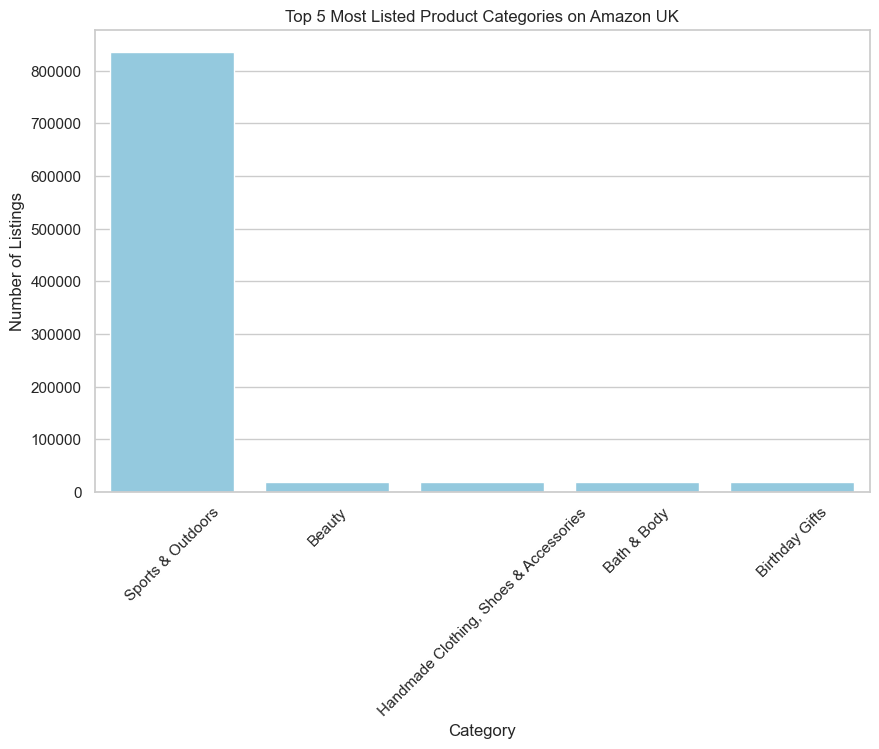

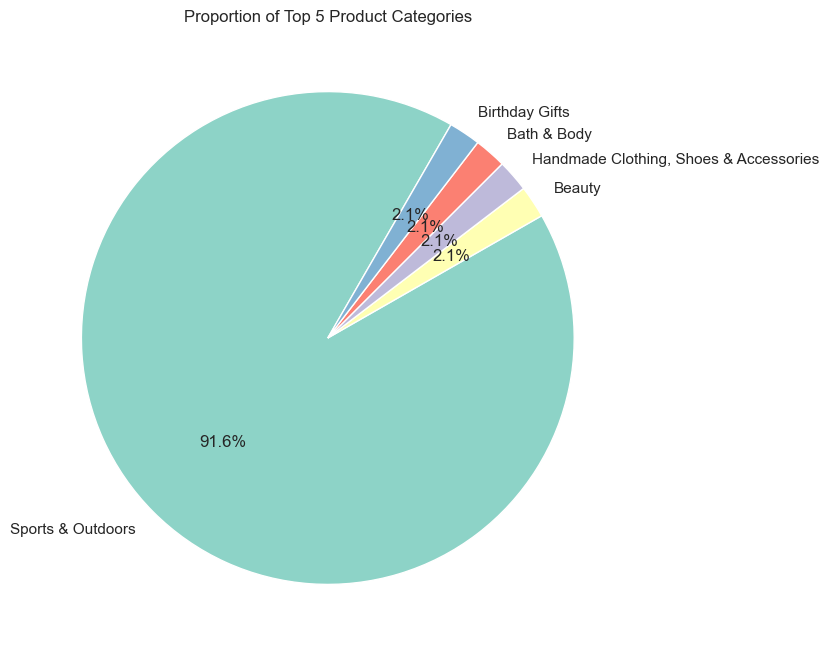

In [50]:
# --- 2.1 Bar Chart: Distribution of Top Categories ---
plt.figure(figsize=(10,6))
sns.barplot(x=top5_categories.index, y=top5_categories.values, color='skyblue')
plt.title("Top 5 Most Listed Product Categories on Amazon UK")
plt.xlabel("Category")
plt.ylabel("Number of Listings")
plt.xticks(rotation=45)
plt.show()

# --- 2.2 Pie Chart: Proportion of Top Categories ---
plt.figure(figsize=(8,8))
plt.pie(top5_categories.values, labels=top5_categories.index, autopct='%1.1f%%',
        startangle=60, colors=sns.color_palette("Set3"))
plt.title("Proportion of Top 5 Product Categories")
plt.show()


In [38]:
#Interpretation

#The dataset shows a clear dominance of Sports & Outdoors,far more than any other category.
#This indicates a highly competitive category.

In [39]:
# ================================================================
# Part 2: Product Pricing Analysis
# ================================================================

# --- 1. Measures of Centrality ---
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean Price: £{mean_price:.2f}")
print(f"Median Price: £{median_price:.2f}")
print(f"Mode Price: £{mode_price:.2f}")


Mean Price: £84.73
Median Price: £19.04
Mode Price: £9.99


In [40]:
# --- 2. Measures of Dispersion ---
variance = df['price'].var()
std_dev = df['price'].std()
price_range = df['price'].max() - df['price'].min()
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

print(f"Variance: {variance:.2f}")
print(f"Standard Deviation: {std_dev:.2f}")
print(f"Range: £{price_range:.2f}")
print(f"IQR: £{IQR:.2f}")


Variance: 76507.07
Standard Deviation: 276.60
Range: £4999.98
IQR: £35.96


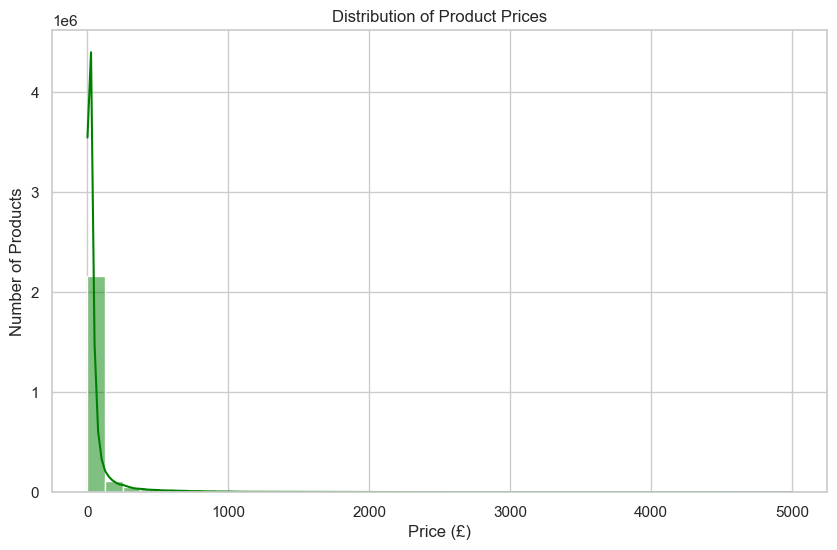

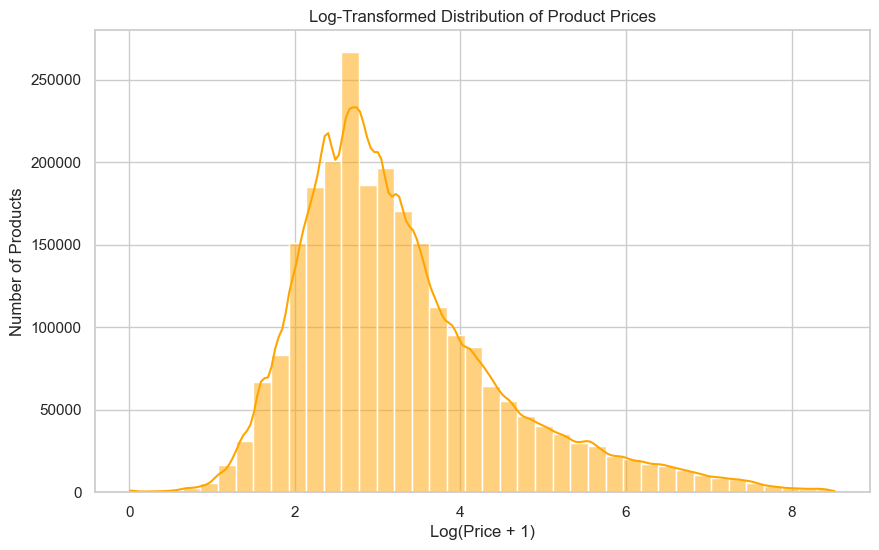

In [54]:
# --- 3.1 Histogram: Price Distribution ---
plt.figure(figsize=(10,6))
sns.histplot(df['price'], bins=40, kde=True, color='green')
plt.title("Distribution of Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Products")
plt.show()

# Log-transformed histogram (better visibility if skewed)
plt.figure(figsize=(10,6))
sns.histplot(np.log1p(df['price']), bins=40, kde=True, color='orange')
plt.title("Log-Transformed Distribution of Product Prices")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Number of Products")
plt.show()


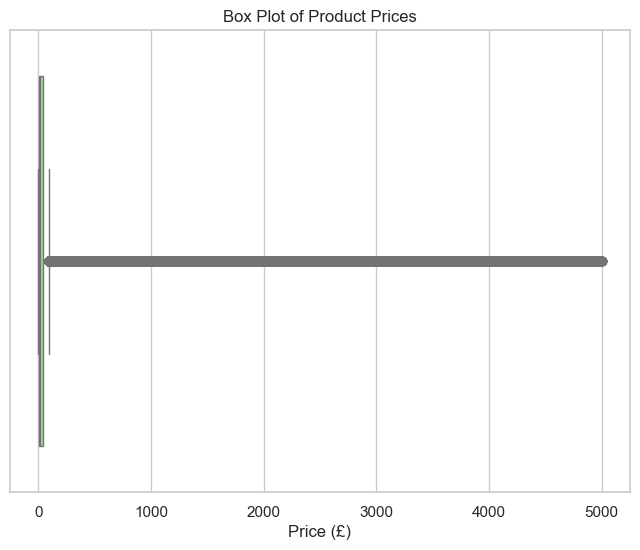

In [42]:
# --- 3.2 Box Plot: Price Spread & Outliers ---
plt.figure(figsize=(8,6))
sns.boxplot(x=df['price'], color='lightgreen')
plt.title("Box Plot of Product Prices")
plt.xlabel("Price (£)")
plt.show()


In [43]:
#Interpretation

#Mean price is much higher than the median and mode, showing a right-skewed distribution: a few expensive items drive the average up.
#Most items are low-cost products.
#The standard deviation and range show that product prices vary dramatically.
#The IQR means that 50% of all items are priced within a moderate range, but there are clear outliers.


In [44]:
# ================================================================
# Part 3: Unpacking Product Ratings
# ================================================================
# We'll use the 'stars' column, which contains product ratings.

# --- Cleaning Stars Column ---
print("Missing star ratings:", df['stars'].isna().sum())

# Drop missing or invalid star ratings
df = df.dropna(subset=['stars'])
df['stars'] = pd.to_numeric(df['stars'], errors='coerce')
df = df.dropna(subset=['stars'])

print("✅ Ratings ('stars') cleaned. Remaining rows:", df.shape[0])


Missing star ratings: 0
✅ Ratings ('stars') cleaned. Remaining rows: 2442121


In [45]:
mean_stars = df['stars'].mean()
median_stars = df['stars'].median()
mode_stars = df['stars'].mode()[0]

print(f"Mean Stars: {mean_stars:.2f}")
print(f"Median Stars: {median_stars:.2f}")
print(f"Mode Stars: {mode_stars:.2f}")


Mean Stars: 2.15
Median Stars: 0.00
Mode Stars: 0.00


In [46]:
variance_stars = df['stars'].var()
std_dev_stars = df['stars'].std()
Q1_stars = df['stars'].quantile(0.25)
Q3_stars = df['stars'].quantile(0.75)
IQR_stars = Q3_stars - Q1_stars

print(f"Variance: {variance_stars:.2f}")
print(f"Standard Deviation: {std_dev_stars:.2f}")
print(f"IQR: {IQR_stars:.2f}")


Variance: 4.82
Standard Deviation: 2.19
IQR: 4.40


In [47]:
from scipy.stats import skew, kurtosis

skewness = skew(df['stars'])
kurt = kurtosis(df['stars'])

print(f"Skewness: {skewness:.2f}")
print(f"Kurtosis: {kurt:.2f}")


Skewness: 0.08
Kurtosis: -1.93


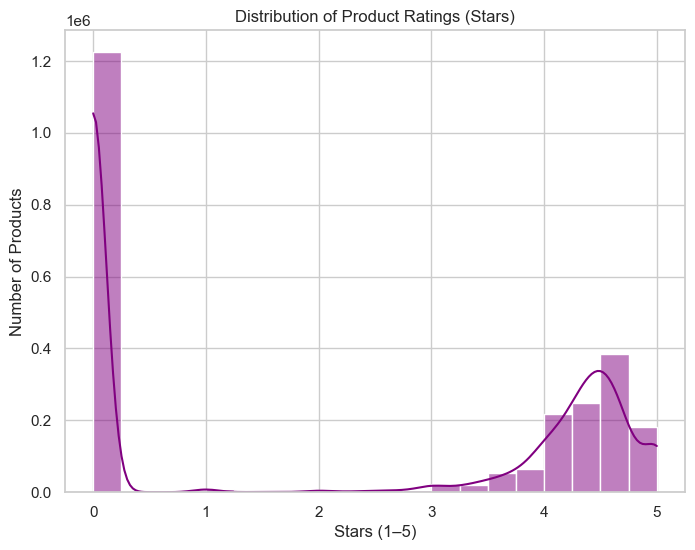

In [48]:
plt.figure(figsize=(8,6))
sns.histplot(df['stars'], bins=20, kde=True, color='purple')
plt.title("Distribution of Product Ratings (Stars)")
plt.xlabel("Stars (1–5)")
plt.ylabel("Number of Products")
plt.show()


In [49]:
#Interpretation

#The mean rating is low, with a median and mode of 0, meaning many products have no ratings at all.
#This is typical of datasets containing new or unrated listings.
#The standard deviation and IQR indicate wide variation.
#Skewness shows near symmetry, but negative kurtosis implies a flatter distribution — ratings are spread rather than clustered.